In [1]:
import os
import pandas as pd

import spacy
import nltk
from dataset_wo_config_files import read_conll_file, make_dict_of_sentences_no_cross
import seaborn as sns
import matplotlib.pyplot as plt


c:\ProgramData\miniconda3\envs\dnlp\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
sp = spacy.load('en_core_web_sm')
spacy_stopwords = sp.Defaults.stop_words

In [3]:
def get_sentences_by_split(dataset_folder, split_name):
    docs_path = os.path.join(dataset_folder + split_name + '/', 'dataset.conll')
    documents, topics = read_conll_file(docs_path)
    sentences_dict = make_dict_of_sentences_no_cross(documents)

    all_sentences = []
    for doc in sentences_dict.values():
        for sentence in doc.values():
            sentence_str = ' '.join([token[2] for token in sentence])
            all_sentences.append(sentence_str)

    return all_sentences

In [4]:
#ECB+:
common_data_folder = "../CDCR/data/"
dataset_name = 'ECBplus-prep'
dataset_folder = f"{common_data_folder}{dataset_name}/output_data/"
split_name = 'train'
ecbplus_sentences_train = get_sentences_by_split(dataset_folder, split_name)

split_name = 'test'
ecbplus_sentences_test = get_sentences_by_split(dataset_folder, split_name)

split_name = 'val'
ecbplus_sentences_val = get_sentences_by_split(dataset_folder, split_name)

ecbplus_sentences = ecbplus_sentences_train + ecbplus_sentences_test + ecbplus_sentences_val


In [5]:
#NewsWCL50:
dataset_name = 'NewsWCL50-prep'
dataset_folder = f"{common_data_folder}{dataset_name}/output_data/"
split_name = 'train'
newswcl50_sentences_train = get_sentences_by_split(dataset_folder, split_name)

split_name = 'test'
newswcl50_sentences_test = get_sentences_by_split(dataset_folder, split_name)

split_name = 'val'
newswcl50_sentences_val = get_sentences_by_split(dataset_folder, split_name)

newswcl50_sentences = newswcl50_sentences_train + newswcl50_sentences_test + newswcl50_sentences_val


In [6]:
# sentences_dict['1/1ecb/1'][2]
# This is going to be key to reproduce CLCOREF

In [7]:
# I need to squeeze the dictionary to create a list of sentences from it. First attempt via 
# Inefficient for loop

In [8]:
# Function to get top tokens
def get_top_tokens(sentences_list, num_tokens=10000):
    # Handle NaN values by converting them to an empty string
    sentences_list = [str(sent) for sent in sentences_list if pd.notna(sent)]
    
    # Join the sentences and tokenize
    tokens = nltk.word_tokenize(" ".join(sentences_list))

    text_without_stopword = [word for word in tokens if word not in spacy_stopwords]

    # Create a frequency distribution of the tokens
    freq_dist = nltk.FreqDist(text_without_stopword)

    # Retrieve the top N most frequent tokens
    top_tokens = freq_dist.most_common(num_tokens)

    # Extract just the tokens (without frequencies)
    top_tokens_only = set([token[0] for token in top_tokens])

    return top_tokens_only


In [9]:
top_10000_ecbplus = get_top_tokens(ecbplus_sentences)
top_10000_newswcl50 = get_top_tokens(newswcl50_sentences)

In [10]:
def jaccard_similarity(set1, set2):
    intersection_size = len(set1.intersection(set2))
    union_size = len(set1.union(set2))
    
    if union_size == 0:
        return 0  # Avoid division by zero
    
    similarity = intersection_size / union_size
    return similarity

In [11]:
jaccard_similarity(top_10000_ecbplus,top_10000_newswcl50)

0.2590011614401858

In [12]:
import pandas as pd

# Specify the directory containing the CSV files
directory_path = r'c:\Users\sago\Documents\GitHub\MBIB\datasets\mbib-aggregated'

# List of CSV files
csv_files = [
    "cognitive-bias.csv",
    "fake-news.csv",
    "gender-bias.csv",
    "hate-speech.csv",
    "linguistic-bias.csv",
    "political-bias.csv",
    "racial-bias.csv",
    "text-level-bias.csv"
]

# Create an empty dictionary to store DataFrames
dataframes_dict = {}

# Load each CSV file into a DataFrame and store in the dictionary
for file_name in csv_files:
    file_path = os.path.join(directory_path, file_name)
    df = pd.read_csv(file_path)
    # Remove file extension to use as the dictionary key
    key = os.path.splitext(file_name)[0]
    dataframes_dict[key] = df

# Now dataframes_dict contains all DataFrames with keys as file names (without extension)


In [32]:
dataframes_dict['cognitive-bias']

,id,text,label,dataset_id
0,072-9268,To vote in Mexico every eligible Mexican citiz...,0,72
1,072-6808,Marco Rubio made it clear Not only does he thi...,0,72
2,072-5150,Ben Carson is running for president to elimina...,0,72
3,072-11817,There are literally teachers now who are getti...,0,72
4,072-7176,Leticia Van de Putte voted to stop schools fro...,0,72
...,...,...,...,...
7087,072-3823,The Trump Winery near Charlottesville Va is th...,1,72
7088,072-4438,Portland Schools spend 500K to deem PBJ sandwi...,1,72
7089,072-2957,A Medicaid provision added to the Senate healt...,1,72
7090,072-12690,I made a bunch of these promises during the ca...,1,72


In [13]:
# Create a new dictionary for processed DataFrames using get_top_tokens function
processed_dataframes_dict = {}

# Process each DataFrame and store the result in the new dictionary
for key, df in dataframes_dict.items():
    sentences_list = df['text'].tolist()
    top_tokens = get_top_tokens(sentences_list)
    processed_dataframes_dict[key] = top_tokens

processed_dataframes_dict["ECBplus"] = set(top_10000_ecbplus)
processed_dataframes_dict["NewsWCL50"] = set(top_10000_newswcl50)

processed_dataframes_dict.pop('fake-news',None)
processed_dataframes_dict.pop('racial-bias',None)

{'goats',
 'shout',
 'foreingers',
 'therell',
 'pissed',
 'mixes',
 'purged',
 'example',
 'yelled',
 'empowerment',
 'frugal',
 'preach',
 'faves',
 'untrue',
 'bothers',
 'critical',
 'wdym',
 'orgy',
 'christina',
 'critique',
 'butch',
 'weve',
 'outspoken',
 'authoritarian',
 'madonna',
 'protective',
 'mashed',
 'initiative',
 'females',
 'fedora',
 'hebrews',
 'oma',
 'reproduce',
 'fad',
 'vegans',
 'subhumans',
 'upvote',
 'dig',
 'entertaining',
 'masters',
 'experienced',
 'encouragement',
 'tittay',
 'honorable',
 'snaps',
 'groupies',
 'copy',
 'shithole',
 'wrinkles',
 'exploitative',
 'warned',
 'slimier',
 'nordic',
 'causality',
 'transsexual',
 'nicer',
 'Song',
 'previously',
 'apple',
 '40',
 'backstory',
 'dosent',
 'portuguese',
 'stephen',
 'clue',
 'towns',
 'DIED',
 'mafioso',
 'robes',
 'riddled',
 'clarified',
 'Beauregard',
 'hoped',
 'ghettos',
 'splash',
 'brazenly',
 'envy',
 'google',
 'fictional',
 'fuckface',
 'whyd',
 'business',
 'germanic',
 'avg',

In [14]:
processed_dataframes_dict.keys()

dict_keys(['cognitive-bias', 'gender-bias', 'hate-speech', 'linguistic-bias', 'political-bias', 'text-level-bias', 'ECBplus', 'NewsWCL50'])

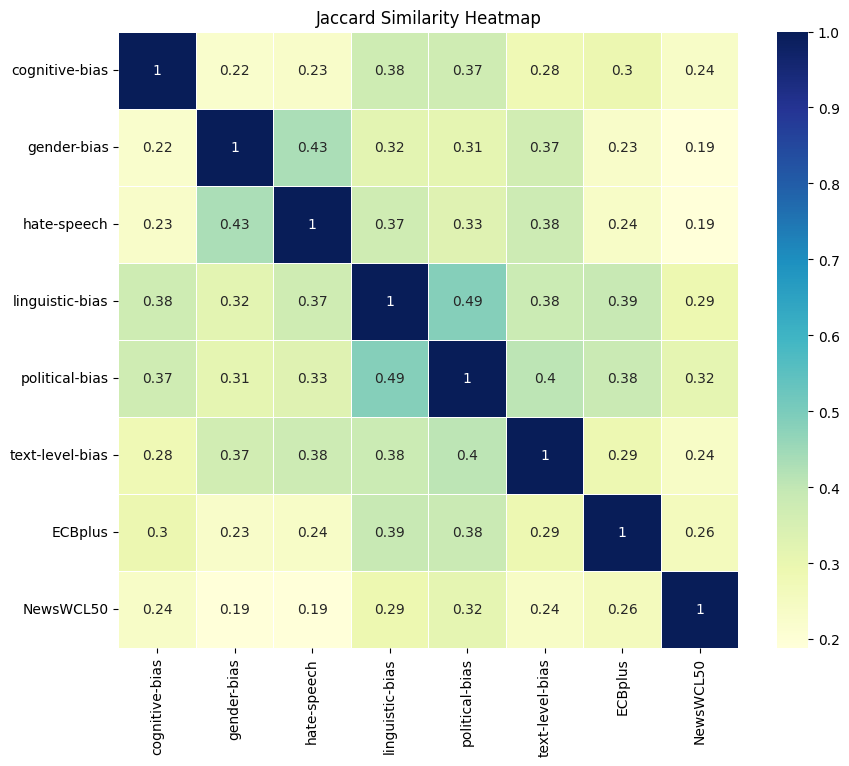

In [15]:

# Calculate Jaccard similarity for all pairs in processed_dataframes_dict
similarity_matrix = pd.DataFrame(index=processed_dataframes_dict.keys(), columns=processed_dataframes_dict.keys())

for key1, set1 in processed_dataframes_dict.items():
    if key1!='fake-news':
        for key2, set2 in processed_dataframes_dict.items():
            if key2!='fake-news':
                similarity_matrix.loc[key1, key2] = jaccard_similarity(set1, set2)

# Convert the dataframe values to numeric
similarity_matrix = similarity_matrix.apply(pd.to_numeric)

# Create a heatmap using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", linewidths=.5)
plt.title("Jaccard Similarity Heatmap")
plt.show()

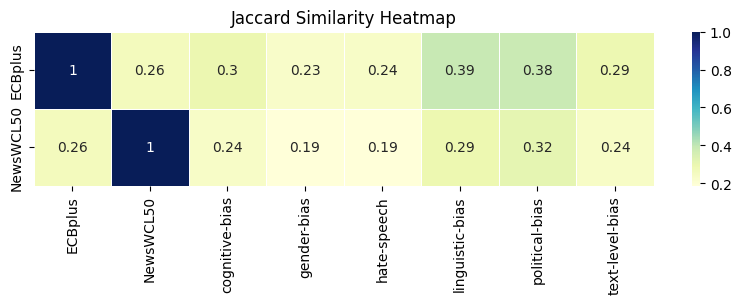

In [16]:
# Extract keys for rows and columns
rows = ['ECBplus', 'NewsWCL50']
columns = ['ECBplus', 'NewsWCL50']
columns.extend([key for key in processed_dataframes_dict if key not in rows])



# Calculate Jaccard similarity for specified pairs
similarity_matrix = pd.DataFrame(index=rows, columns=columns)

for row_key in rows:
    for col_key in columns:
        similarity_matrix.loc[row_key, col_key] = jaccard_similarity(
            processed_dataframes_dict[row_key], processed_dataframes_dict[col_key]
        )

# Convert the dataframe values to numeric
similarity_matrix = similarity_matrix.apply(pd.to_numeric)

# Create a heatmap using seaborn
plt.figure(figsize=(10, 2))
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", linewidths=.5, square=False)
plt.title("Jaccard Similarity Heatmap")
plt.show()

## Validation with MBIB from huggingface

In [17]:
from datasets import load_dataset

config_names = [
    "cognitive-bias",
    "gender-bias",
    "hate-speech",
    "linguistic-bias",
    "political-bias",
    "text-level-bias"
]

dataset_huggingface_dict = {}

for config_name in config_names:
    dataset = load_dataset("mediabiasgroup/mbib-base", config_name)
    dataset_huggingface_dict[config_name] = dataset

# Access a specific dataset, for example, the "cognitive-bias" dataset
cognitive_bias_dataset = dataset_huggingface_dict["cognitive-bias"]


In [18]:
for key in dataset_huggingface_dict.keys():
    print(key)
    print(len(dataframes_dict[key]))
    print(dataset_huggingface_dict[key].num_rows)
    print('-----')

cognitive-bias
7092
{'train': 7092}
-----
gender-bias
17940
{'train': 17940}
-----
hate-speech
24996
{'train': 339010}
-----
linguistic-bias
401862
{'train': 401862}
-----
political-bias
17704
{'train': 17704}
-----
text-level-bias
9018
{'train': 9018}
-----


In [19]:
df['train']['text']

KeyError: 'train'

In [ ]:
processed_huggingface_dataframes_dict['cognitive-bias']

{'Protestant',
 'buyer',
 'Superintendent',
 'Ed',
 '2003',
 'prisoners',
 'Camilo',
 '9',
 'Alison',
 'mutual',
 'afloat',
 'ample',
 'ensuring',
 'Nazi',
 'Amash',
 'loudly',
 'pipes',
 'insecurity',
 'trucks',
 'wound',
 'fluorescent',
 'lease',
 'prosperity',
 'Lt',
 'ham',
 'anybody',
 'Business',
 'Expanding',
 'marketed',
 'Aboard',
 'intelligent',
 'role',
 'parliament',
 'peoples',
 'referral',
 '443',
 'Carrier',
 'imminent',
 'confronting',
 'Marijuana',
 'lower',
 'despise',
 'Lake',
 'terrorism',
 'promptly',
 'Daugherty',
 'tractor',
 'hurt',
 'dropout',
 'uncertainty',
 'Aggie',
 'mismanagement',
 'seeing',
 'ineffective',
 'anthem',
 'investors',
 'Post',
 'services',
 'Batman',
 '13th',
 'won',
 'southern',
 'Dhimmitude',
 'elaborate',
 'HIPAA',
 'Joe',
 'Hospital',
 'rebel',
 'ad',
 'Staples',
 '878',
 'cosponsored',
 'apply',
 'Pawlenty',
 'groped',
 'Utility',
 'Resources',
 'clinical',
 'hes',
 'refuses',
 'ozone',
 'Pallone',
 'Says',
 'reduce',
 'Intelligence',
 

In [ ]:
# Create a new dictionary for processed DataFrames using get_top_tokens function
processed_huggingface_dataframes_dict = {}

# Process each DataFrame and store the result in the new dictionary
for key, df in dataset_huggingface_dict.items():
    print(df)
    sentences_list = df['train']['text']
    top_tokens = get_top_tokens(sentences_list)
    processed_huggingface_dataframes_dict[key] = top_tokens

processed_huggingface_dataframes_dict["ECBplus"] = set(top_10000_ecbplus)
processed_huggingface_dataframes_dict["NewsWCL50"] = set(top_10000_newswcl50)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 7092
    })
})
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 17940
    })
})
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 339010
    })
})
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 401862
    })
})
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 17704
    })
})
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 9018
    })
})


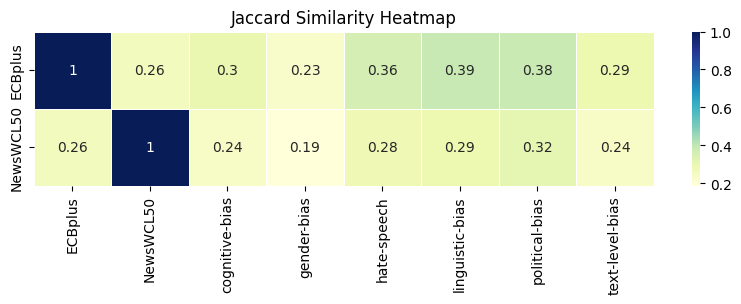

In [ ]:
# Extract keys for rows and columns
rows = ['ECBplus', 'NewsWCL50']
columns = ['ECBplus', 'NewsWCL50']
columns.extend([key for key in processed_huggingface_dataframes_dict if key not in rows])



# Calculate Jaccard similarity for specified pairs
similarity_matrix = pd.DataFrame(index=rows, columns=columns)

for row_key in rows:
    for col_key in columns:
        similarity_matrix.loc[row_key, col_key] = jaccard_similarity(
            processed_huggingface_dataframes_dict[row_key], processed_huggingface_dataframes_dict[col_key]
        )

# Convert the dataframe values to numeric
similarity_matrix = similarity_matrix.apply(pd.to_numeric)

# Create a heatmap using seaborn
plt.figure(figsize=(10, 2))
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", linewidths=.5, square=False)
plt.title("Jaccard Similarity Heatmap")
plt.show()

In [20]:
### Check average document size

In [30]:
# Calculate average length for each dataset
for dataset_name, dataset_data in dataset_huggingface_dict.items():
    string_list = dataset_data['train']['text']
    average_length = sum(len(s) for s in string_list) / len(string_list)
    
    print(f"Average length of strings in {dataset_name}: {average_length}")

Average length of strings in cognitive-bias: 103.86449520586577
Average length of strings in gender-bias: 86.73651059085842
Average length of strings in hate-speech: 273.6537329282322
Average length of strings in linguistic-bias: 282.5721914488058
Average length of strings in political-bias: 222.76824446452778
Average length of strings in text-level-bias: 186.47105788423153


'Austins Stop Abuse for Everyone has seen in its offices sexual assault survivors that report being attacked by their ridesharing drivers at a rate of one per month '